# Численные методы решения нелинейных уравнений
## Вариант 2
$x + \sqrt{x} + \sqrt[3]{x} -2.5 = 0$
## Основная часть
Построение графика функции

In [167]:
import matplotlib.pyplot as plt
from scipy.differentiate import derivative 
import numpy as np

In [168]:
def f(x):
    return x + np.sqrt(x) + np.cbrt(x) - 2.5

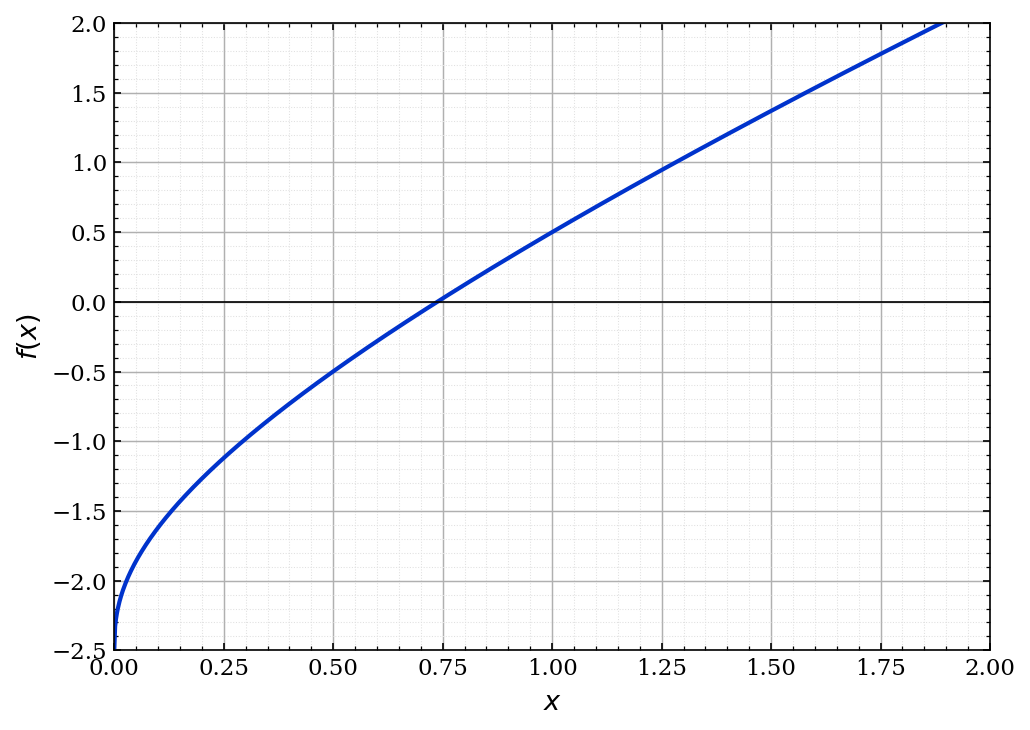

In [169]:
x = np.linspace(0, 2.0, 1000)
y = f(x)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

ax.plot(x, y, color='#0033cc', linewidth=2)
ax.axhline(0, color='black', linewidth=0.8)

ax.grid(visible=True, which='major', color='#b0b0b0', linestyle='-', linewidth=0.7)
ax.grid(visible=True, which='minor', color='#e0e0e0', linestyle=':', linewidth=0.5)
ax.minorticks_on()

ax.tick_params(which='both', direction='in', top=True, right=True)

ax.set_xlim(0, 2.0)
ax.set_ylim(-2.5, 2.0)
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$f(x)$', fontsize=13)

plt.tight_layout()
plt.show()

Уточним график

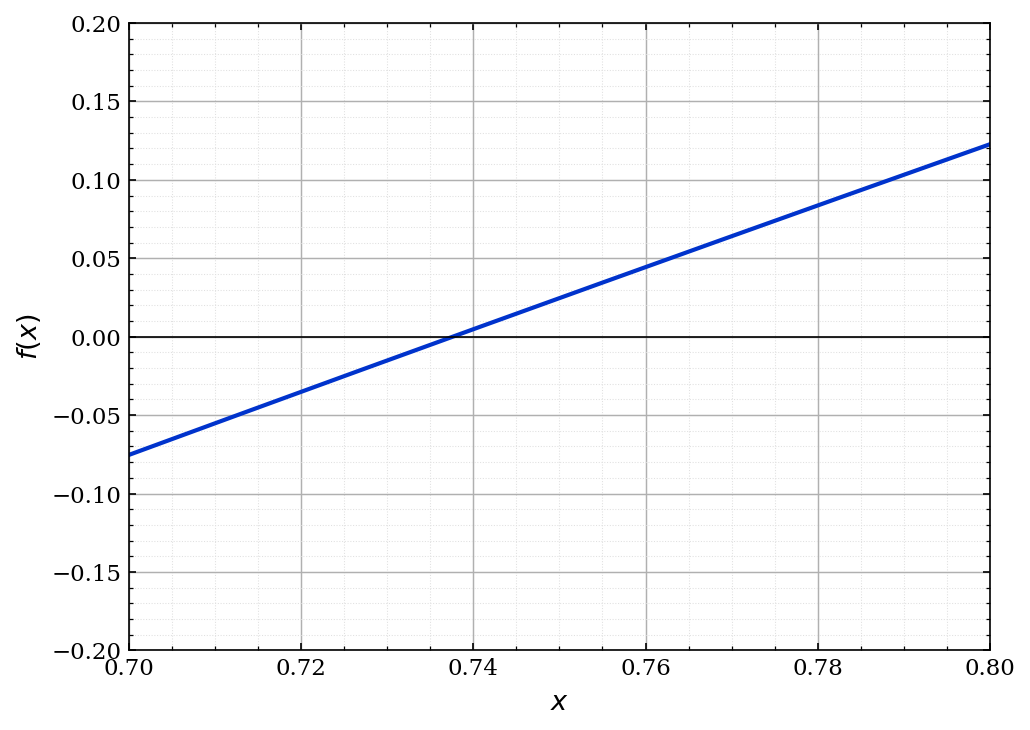

In [170]:
x = np.linspace(0, 2.0, 1000)
y = f(x)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

ax.plot(x, y, color='#0033cc', linewidth=2)
ax.axhline(0, color='black', linewidth=0.8)

ax.grid(visible=True, which='major', color='#b0b0b0', linestyle='-', linewidth=0.7)
ax.grid(visible=True, which='minor', color='#e0e0e0', linestyle=':', linewidth=0.5)
ax.minorticks_on()

ax.tick_params(which='both', direction='in', top=True, right=True)

ax.set_xlim(0.7, 0.8)
ax.set_ylim(-0.2, 0.2)
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$f(x)$', fontsize=13)

plt.tight_layout()
plt.show()

На графике один корень $x \approx 0.735$ (нижняя граница)
## Реализация методов дихотомии, простой итерации и Ньютона

Метод дихотомии

In [171]:
def dichotomy_step(a,b):
    if f(a) * f((a+b)/2) <= 0:
        return a,(a+b)/2
    else:
        return (a+b)/2,b

def dichotomy (n, a, b):
    for i in range(n):
        a,b = dichotomy_step(a,b)
    return (a+b)/2

Метод итерации

Преобразуем уравнение к виду: $x = 2.5 - \sqrt{x} - \sqrt[3]{x}$

Для сходимости метода простых итераций требуется выполнение условия $|\varphi'(x)| < 1$. 

Оценим модуль полученной производной в окрестности корня (при $x \ge 0.735$):
$|\varphi'(x)| = \left| -\frac{1}{2\sqrt{x}} - \frac{1}{3\sqrt[3]{x^2}} \right| = \frac{1}{2\sqrt{x}} + \frac{1}{3\sqrt[3]{x^2}} = 0.99249... < 1$

Следовательно, в окрестности корня выполняется строгое неравенство:
$|\varphi'(x)| < 1$

In [212]:
def simple_iteration_step(x):
    x_ns = 2.5 - np.sqrt(x) - np.cbrt(x)
    return x_ns

def simple_iteration(x, n):
    for i in range(n):
        x = simple_iteration_step(x)
    return x

Метод Ньютона

In [217]:
def newton_step(x):
    x_n = x - f(x)/derivative(f,x).df
    return x_n

def newton(x, n):
    for i in range(n):
        x = newton_step(x)
    return x

## Нахождение корня

Метод дихотомии

In [292]:
A = 0.0001
n = int(np.ceil(np.log2((0.74 - 0.735) / (2 * A))))
print('x=',dichotomy(n, 0.735, 0.74))
print('n=',n)

x= 0.737578125
n= 5


In [293]:
A = 0.000001
n = int(np.ceil(np.log2((0.74 - 0.735) / (2 * A))))
print('x=',dichotomy(n, 0.735, 0.74))
print('n=',n)

x= 0.7376190185546875
n= 12


In [294]:
A = 0.0000000000000001
n = int(np.ceil(np.log2((0.74 - 0.735) / (2 * A))))
print('x=',dichotomy(n, 0.735, 0.74))
print('n=',n)

x= 0.7376192462774627
n= 45


In [296]:
A = 0.000000000000000000000000001
n = int(np.ceil(np.log2((0.74 - 0.735) / (2 * A))))
print('x=',dichotomy(n, 0.735, 0.74))
print('n=',n)

x= 0.7376192462774627
n= 82


В методе дихотомии корень определяется с точностью до пороговой точности вычисления компьютера. Число итераций требуется большое

Метод Ньютона

In [290]:
A = 0.00001

x_n = 0.735
x_n1 = newton(x_n, 1)
n = 1
while (np.abs(x_n - x_n1) >= A):
    n += 1
    x_n = x_n1
    x_n1 = newton(0.735, n)
print('x=',x_n1)
print('n=',n)

x= 0.7376192462771286
n= 2


In [291]:
A = 0.000000001

x_n = 0.735
x_n1 = newton(x_n, 1)
n = 1
while (np.abs(x_n - x_n1) >= A):
    n += 1
    x_n = x_n1
    x_n1 = newton(0.735, n)
print('x=',x_n1)
print('n=',n)

x= 0.7376192462774628
n= 3


In [289]:
A = 0.0000000000001

x_n = 0.735
x_n1 = newton(x_n, 1)
n = 1
while (np.abs(x_n - x_n1) >= A):
    n += 1
    x_n = x_n1
    x_n1 = newton(0.735, n)
print('x=',x_n1)
print('n=',n)

x= 0.7376192462774628
n= 4


В методе Ньютона корень определяется с точностью до пороговой точности вычисления компьютера. Число итераций требуется малое

Метод итераций

In [281]:
A = 0.5

x_n = 0.735
x_n1 = simple_iteration(x_n, 1)
x_n2 = simple_iteration(x_n, 2)
n = 2

while (np.abs(x_n2 - x_n1)/np.abs(2*x_n1-x_n2-x_n) >= A):
    n += 1
    x_n = x_n1
    x_n1 = x_n2
    x_n2 = simple_iteration(0.735, n)
    
print('x=',x_n2) 
print('n=',n)

x= 0.7350495729210237
n= 2


In [279]:
A = 0.4969

x_n = 0.735
x_n1 = simple_iteration(x_n, 1)
x_n2 = simple_iteration(x_n, 2)
n = 2

while (np.abs(x_n2 - x_n1)/np.abs(2*x_n1-x_n2-x_n) >= A):
    n += 1
    x_n = x_n1
    x_n1 = x_n2
    x_n2 = simple_iteration(0.735, n)
    
print('x=',x_n2) 
print('n=',n)

x= 0.7376192462774023
n= 2562


In [280]:
A = 0.4968

x_n = 0.735
x_n1 = simple_iteration(x_n, 1)
x_n2 = simple_iteration(x_n, 2)
n = 2

while (np.abs(x_n2 - x_n1)/np.abs(2*x_n1-x_n2-x_n) >= A):
    n += 1
    x_n = x_n1
    x_n1 = x_n2
    x_n2 = simple_iteration(0.735, n)
    
print('x=',x_n2) 
print('n=',n)

x= 0.7376192462774378
n= 2656


Видно, что при уменьшении А в последнем способе число шагов кратно возрастает. Число итераций требуется недостижимо большое для определния числа с точностью до пороговой точности вычисления компьютера